In [1]:
import pandas as pd
import numpy as np

In [2]:
import re
from pathlib import Path
import pandas as pd

FOLDER = Path("/Users/suppanatp/Documents/NUS FE/2 Courses/FE5209 FINANCIAL ECONOMETRICS/Project/AlgoGoneCrazy/visualization/data")   # แก้เป็น path ของคุณ

def to_name(stem: str) -> str:
    name = re.sub(r"\W+", "_", stem).strip("_").lower()
    if name and name[0].isdigit():   # ชื่อตัวแปรขึ้นต้นด้วยตัวเลขไม่ได้
        name = "df_" + name
    return f"{name}_df"

dfs = {}
for f in sorted(FOLDER.glob("*.csv")):
    dfs[to_name(f.stem)] = pd.read_csv(f)
    print(f"{f.name:30} -> {to_name(f.stem):25} {len(dfs[to_name(f.stem)]):,} rows")

backfilled_market_bars_30m.csv -> backfilled_market_bars_30m_df 20 rows
incomplete_market_bars_30m.csv -> incomplete_market_bars_30m_df 20 rows
market_bars_30m.csv            -> market_bars_30m_df        3,939 rows
market_bars_30m_with_backfill.csv -> market_bars_30m_with_backfill_df 3,959 rows
market_bars_5m.csv             -> market_bars_5m_df         23,739 rows
market_session_coverage.csv    -> market_session_coverage_df 180 rows
missing_market_bars_5m.csv     -> missing_market_bars_5m_df 20 rows
rejected_market_bars_5m.csv    -> rejected_market_bars_5m_df 620 rows
unresolved_market_bars_30m.csv -> unresolved_market_bars_30m_df 0 rows


In [3]:
pd.set_option("display.max_columns", None)

In [4]:
dfs['market_bars_30m_df']['source'].value_counts()

binance_spot     2831
yahoo_finance    1108
Name: source, dtype: int64

In [5]:
dfs['market_bars_30m_df']['%change'] = dfs['market_bars_30m_df'].groupby('instrument_id')['close'].pct_change() * 100

In [6]:
dfs['market_bars_30m_df']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 04:30:00+00:00,2026-07-01 05:00:00+00:00,2026-07-01,59274.000,59457.000,59200.000,59339.990,59339.990,325.49941,BTC,1.931938e+07,USDT,63774.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,59339.990,59376.480,59154.020,59174.000,59174.000,319.60119,BTC,1.894897e+07,USDT,55643.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.279727
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,59174.000,59204.430,59126.420,59154.330,59154.330,112.70368,BTC,6.668226e+06,USDT,31850.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.033241
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,59154.330,59156.000,58692.000,58791.160,58791.160,334.28162,BTC,1.969248e+07,USDT,78534.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.613936
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,58791.160,58834.850,58534.310,58755.800,58755.800,459.85239,BTC,2.698495e+07,USDT,71378.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.060145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128


# Plotting

## Closing Price

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Fixed categorical color slots (blue, orange, aqua, ...) assigned by product
# in a stable order, so a given product always gets the same color across plots.
PRODUCT_COLORS = {
    'btc_usdt': '#2a78d6',
    'spy_usd': '#eb6834',
    'sti_es3_sgd': '#1baf7a',
}


def plot_series(
    df,
    instrument_id,
    label=None,
    color=None,
    time_col='bar_close_time_utc',
    val_col='close',
    figsize=(11, 4),
):
    """Plot the closing price over time for a single product/instrument."""
    sub = df[df['instrument_id'] == instrument_id].copy()
    sub[time_col] = pd.to_datetime(sub[time_col])
    sub = sub.sort_values(time_col)

    label = label or instrument_id
    color = color or PRODUCT_COLORS.get(instrument_id, '#2a78d6')

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('#fcfcfb')
    ax.set_facecolor('#fcfcfb')

    ax.plot(sub[time_col], sub[val_col], color=color, linewidth=1.5)
    ax.set_title(f'{label} — {val_col.capitalize()} Over Time', loc='left', fontsize=12, color='#0b0b0b')
    ax.set_ylabel(val_col.capitalize(), color='#52514e', fontsize=9)
    ax.grid(True, color='#e1e0d9', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#c3c2b7')
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(colors='#898781', labelsize=9)

    # Let matplotlib pick a sparse set of date ticks rather than labeling every bar.
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    fig.tight_layout()
    plt.show()
    return fig, ax

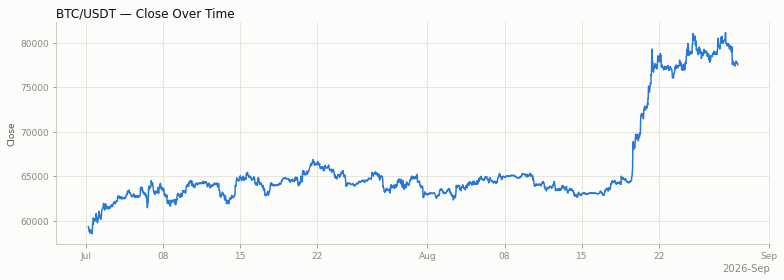

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f42091940>)

In [8]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='close')

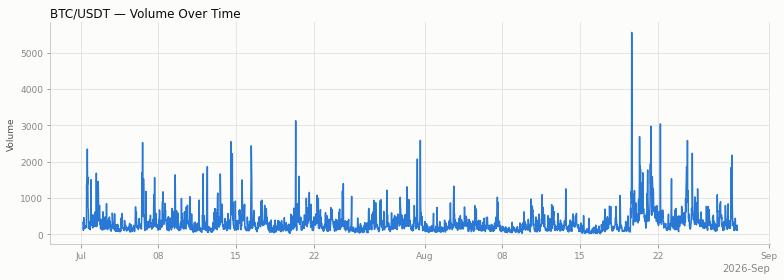

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f41a5fb80>)

In [9]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='volume')

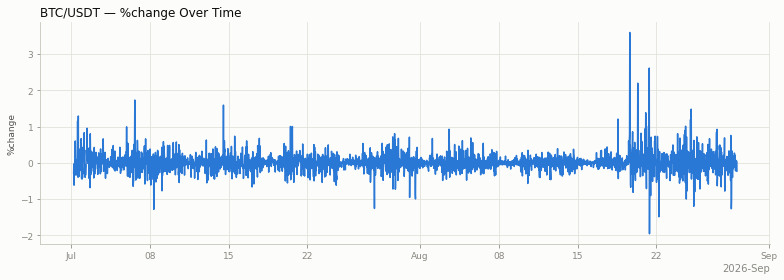

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f420918e0>)

In [10]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='%change')

In [11]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt']['%change'].describe()

count    2830.000000
mean        0.009789
std         0.265419
min        -1.951777
25%        -0.103961
50%         0.000103
75%         0.112265
max         3.593090
Name: %change, dtype: float64

In [12]:
dfs['market_bars_30m_df']['instrument_id'].value_counts()

btc_usdt       2831
sti_es3_sgd     562
spy_usd         546
Name: instrument_id, dtype: int64

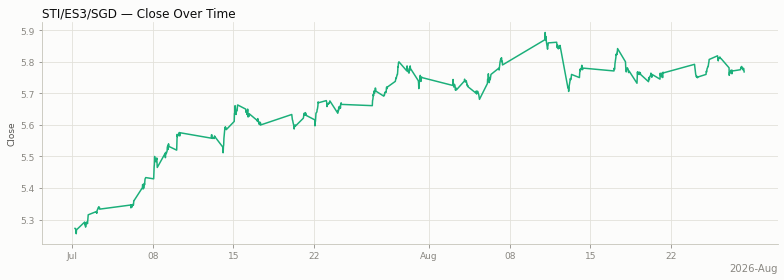

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f52372fa0>)

In [13]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='close')

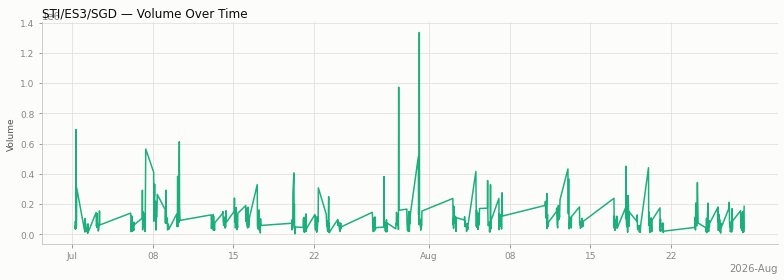

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f51b02160>)

In [14]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='volume')

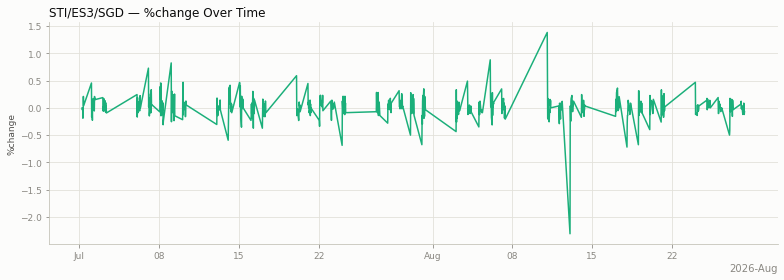

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f41a8f4c0>)

In [15]:
plot_series(dfs['market_bars_30m_df'], 'sti_es3_sgd', label='STI/ES3/SGD', val_col='%change')

In [16]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'sti_es3_sgd']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change
3377,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,5.279,5.279,5.269,5.272,5.272,82965.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN
3378,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,5.272,5.272,5.270,5.272,5.272,34034.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3379,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,5.272,5.276,5.267,5.270,5.270,57668.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.037934
3380,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,5.270,5.275,5.265,5.270,5.270,35588.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3381,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-07-01 07:00:00+00:00,2026-07-01 07:30:00+00:00,2026-07-01,5.270,5.273,5.258,5.260,5.260,692692.0,units,NaN,SGD,NaN,True,6,6,1.0,warning,zero_volume,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.189749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.0,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128


In [17]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'sti_es3_sgd']['bar_close_time_utc'].head(50)

3377    2026-07-01 05:30:00+00:00
3378    2026-07-01 06:00:00+00:00
3379    2026-07-01 06:30:00+00:00
3380    2026-07-01 07:00:00+00:00
3381    2026-07-01 07:30:00+00:00
3382    2026-07-01 08:00:00+00:00
3383    2026-07-01 08:30:00+00:00
3384    2026-07-01 09:00:00+00:00
3385    2026-07-02 01:30:00+00:00
3386    2026-07-02 02:00:00+00:00
3387    2026-07-02 02:30:00+00:00
3388    2026-07-02 03:00:00+00:00
3389    2026-07-02 03:30:00+00:00
3390    2026-07-02 04:00:00+00:00
3391    2026-07-02 05:30:00+00:00
3392    2026-07-02 06:00:00+00:00
3393    2026-07-02 06:30:00+00:00
3394    2026-07-02 07:00:00+00:00
3395    2026-07-02 07:30:00+00:00
3396    2026-07-02 08:00:00+00:00
3397    2026-07-02 08:30:00+00:00
3398    2026-07-02 09:00:00+00:00
3399    2026-07-03 01:30:00+00:00
3400    2026-07-03 02:00:00+00:00
3401    2026-07-03 02:30:00+00:00
3402    2026-07-03 03:00:00+00:00
3403    2026-07-03 03:30:00+00:00
3404    2026-07-03 04:00:00+00:00
3405    2026-07-03 06:00:00+00:00
3406    2026-0

In [18]:
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'sti_es3_sgd']['close'].head(20)

3377    5.272
3378    5.272
3379    5.270
3380    5.270
3381    5.260
3382    5.255
3383    5.266
3384    5.268
3385    5.292
3386    5.283
3387    5.290
3388    5.288
3389    5.276
3390    5.282
3391    5.291
3392    5.292
3393    5.292
3394    5.290
3395    5.287
3396    5.298
Name: close, dtype: float64

In [19]:
def add_rsi(df, price_col='close', period=14, group_col='instrument_id', time_col='bar_close_time_utc'):
    """Add a Wilder's RSI column (momentum, 0-100) to df, computed per instrument."""
    df = df.sort_values([group_col, time_col])

    delta = df.groupby(group_col)[price_col].diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.groupby(df[group_col]).transform(
        lambda s: s.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    )
    avg_loss = loss.groupby(df[group_col]).transform(
        lambda s: s.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    )

    rs = avg_gain / avg_loss
    df['rsi'] = 100 - (100 / (1 + rs))
    return df

In [20]:
dfs['market_bars_30m_df'] = add_rsi(dfs['market_bars_30m_df'])
dfs['market_bars_30m_df'][dfs['market_bars_30m_df']['instrument_id'] == 'btc_usdt']['rsi'].describe()

count    2817.000000
mean       51.832637
std        11.863776
min        16.424010
25%        43.822558
50%        51.701354
75%        59.365236
max        95.776653
Name: rsi, dtype: float64

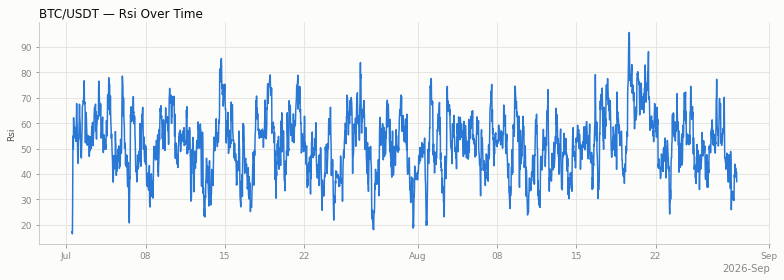

(<Figure size 792x288 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f41f32070>)

In [21]:
plot_series(dfs['market_bars_30m_df'], 'btc_usdt', label='BTC/USDT', val_col='rsi')

In [22]:
dfs['market_bars_30m_df']

,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_open_time_utc,bar_close_time_utc,session_date_local,open,high,low,close,adjusted_close,volume,volume_unit,quote_volume,quote_currency,trade_count,is_final,expected_subbar_count,actual_subbar_count,coverage_ratio,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,%change,rsi
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 04:30:00+00:00,2026-07-01 05:00:00+00:00,2026-07-01,59274.000,59457.000,59200.000,59339.990,59339.990,325.49941,BTC,1.931938e+07,USDT,63774.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,NaN,NaN
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:00:00+00:00,2026-07-01 05:30:00+00:00,2026-07-01,59339.990,59376.480,59154.020,59174.000,59174.000,319.60119,BTC,1.894897e+07,USDT,55643.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.279727,NaN
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 05:30:00+00:00,2026-07-01 06:00:00+00:00,2026-07-01,59174.000,59204.430,59126.420,59154.330,59154.330,112.70368,BTC,6.668226e+06,USDT,31850.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.033241,NaN
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:00:00+00:00,2026-07-01 06:30:00+00:00,2026-07-01,59154.330,59156.000,58692.000,58791.160,58791.160,334.28162,BTC,1.969248e+07,USDT,78534.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.613936,NaN
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,2026-07-01 06:30:00+00:00,2026-07-01 07:00:00+00:00,2026-07-01,58791.160,58834.850,58534.310,58755.800,58755.800,459.85239,BTC,2.698495e+07,USDT,71378.0,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.060145,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3934,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 06:30:00+00:00,2026-08-28 07:00:00+00:00,2026-08-28,5.775,5.777,5.769,5.774,5.774,150799.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.017315,44.267435
3935,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:00:00+00:00,2026-08-28 07:30:00+00:00,2026-08-28,5.774,5.779,5.772,5.779,5.779,95572.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.086589,49.030716
3936,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 07:30:00+00:00,2026-08-28 08:00:00+00:00,2026-08-28,5.779,5.781,5.772,5.779,5.779,14479.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,0.000000,49.030716
3937,sti_es3_sgd,yahoo_finance,ES3.SI,equity_etf,SGX,30m,5m,derived_from_5m,v1,2026-08-28 08:00:00+00:00,2026-08-28 08:30:00+00:00,2026-08-28,5.779,5.779,5.772,5.772,5.772,48470.00000,units,NaN,SGD,NaN,True,6,6,1.0,pass,NaN,2026-08-29 04:01:12.115331+00:00,2026-08-29 04:03:28.832005+00:00,-0.121128,43.055510


## RSI Momentum Check: Forward Return by Regime

For each bar, look `n` steps ahead and measure the % price change. Compare that
forward return when RSI was oversold (< 35) vs overbought (> 65) at the starting
bar.

In [23]:
def add_forward_return(df, periods=10, price_col='close', group_col='instrument_id', time_col='bar_close_time_utc'):
    """Add a forward % return column: change from t to t+periods bars ahead, per instrument."""
    df = df.sort_values([group_col, time_col])
    df[f'fwd_return_{periods}'] = df.groupby(group_col)[price_col].transform(
        lambda s: (s.shift(-periods) - s) / s * 100
    )
    return df


dfs['market_bars_30m_df'] = add_forward_return(dfs['market_bars_30m_df'], periods=10)

In [24]:
def rsi_regime_stats(df, low=35, high=65, periods=10, rsi_col='rsi', group_col='instrument_id'):
    """Compare forward returns following an oversold (rsi < low) vs overbought (rsi > high) reading."""
    ret_col = f'fwd_return_{periods}'
    oversold = df.loc[df[rsi_col] < low, ret_col].dropna()
    overbought = df.loc[df[rsi_col] > high, ret_col].dropna()

    summary = pd.DataFrame({
        f'oversold (rsi<{low})': oversold.describe(),
        f'overbought (rsi>{high})': overbought.describe(),
    })

    by_instrument = df.assign(
        regime=np.select(
            [df[rsi_col] < low, df[rsi_col] > high],
            ['oversold', 'overbought'],
            default=None,
        )
    ).dropna(subset=['regime', ret_col]).groupby([group_col, 'regime'])[ret_col].agg(['count', 'mean', 'median', 'std'])

    return summary, by_instrument, oversold, overbought


summary, by_instrument, oversold, overbought = rsi_regime_stats(dfs['market_bars_30m_df'], low=35, high=65, periods=10)
summary

,oversold (rsi<35),overbought (rsi>65)
count,299.000000,625.000000
mean,0.226315,0.201405
std,0.714300,0.934461
min,-1.944195,-2.512250
25%,-0.085481,-0.331487
50%,0.197989,0.034432
75%,0.519859,0.527603
max,3.742482,6.371240


In [25]:
by_instrument

count      mean    median       std
instrument_id regime                                         
btc_usdt      overbought    386  0.190084 -0.046656  1.081016
              oversold      223  0.196776  0.164897  0.779789
spy_usd       overbought     79  0.176628  0.016719  0.687412
              oversold       55  0.200605  0.218657  0.428922
sti_es3_sgd   overbought    160  0.240950  0.200443  0.602781
              oversold       21  0.607332  0.592746  0.438231

/Users/suppanatp/opt/anaconda3/lib/python3.9/site-packages/matplotlib/cbook/__init__.py:1376: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  X = np.atleast_1d(X.T if isinstance(X, np.ndarray) else np.asarray(X))


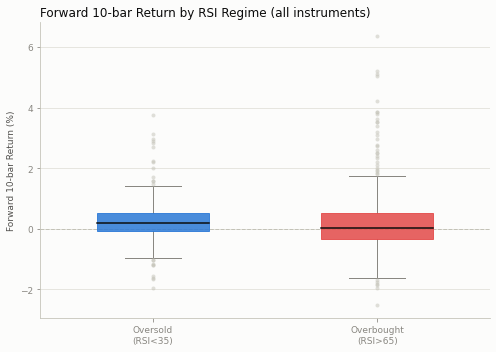

(<Figure size 504x360 with 1 Axes>,
 <matplotlib.axes._subplots.AxesSubplot at 0x7f7f51da8ca0>)

In [26]:
# Diverging blue/red: oversold (bullish reversal expected) vs overbought (bearish
# reversal expected) are opposite momentum states, so the diverging pair reads as
# "opposite," unlike the per-product PRODUCT_COLORS used for identity elsewhere.
REGIME_COLORS = {'oversold': '#2a78d6', 'overbought': '#e34948'}


def plot_regime_comparison(oversold, overbought, periods=10, figsize=(7, 5)):
    """Box-plot the forward-return distribution for oversold vs overbought RSI readings."""
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('#fcfcfb')
    ax.set_facecolor('#fcfcfb')

    bp = ax.boxplot(
        [oversold, overbought],
        labels=['Oversold\n(RSI<35)', 'Overbought\n(RSI>65)'],
        patch_artist=True,
        widths=0.5,
        medianprops=dict(color='#0b0b0b', linewidth=1.5),
        whiskerprops=dict(color='#898781'),
        capprops=dict(color='#898781'),
        flierprops=dict(markerfacecolor='#c3c2b7', markeredgecolor='none', markersize=4, alpha=0.5),
    )
    for patch, color in zip(bp['boxes'], REGIME_COLORS.values()):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)
        patch.set_edgecolor(color)

    ax.axhline(0, color='#c3c2b7', linewidth=1, linestyle='--')
    ax.set_ylabel(f'Forward {periods}-bar Return (%)', color='#52514e', fontsize=9)
    ax.set_title(f'Forward {periods}-bar Return by RSI Regime (all instruments)', loc='left', fontsize=12, color='#0b0b0b')
    ax.grid(True, axis='y', color='#e1e0d9', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#c3c2b7')
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(colors='#898781', labelsize=9)

    fig.tight_layout()
    plt.show()
    return fig, ax


plot_regime_comparison(oversold, overbought, periods=10)